# The Maß Index: 40 years of Oktoberfest prices vs German inflation

The Economist has its Big Mac Index. Munich has the **Maß**, the one-litre beer mug at the Oktoberfest. The city publishes its average price every year, so it makes a surprisingly good economic indicator.

**Questions**

1. How much more does a Maß cost than in 1985, and how much of that is just inflation?
2. How many minutes does someone on minimum wage work for one?
3. Which tents are cheapest, and is the gap growing?
4. Has food at the Wiesn risen faster than beer, and faster than inflation?
5. If prices keep rising, when will a Maß cost 20 €?

**Data:** City of Munich open data (Oktoberfest totals 1985-2025, beer price per tent 2000-2025, menu prices 2018-2025), the Destatis consumer price index (table 61111-0001), the statutory minimum wage, and the Destatis wage index for Bavaria (table 62361-0102).

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
import wiesn

IMG = ROOT / "images"
IMG.mkdir(exist_ok=True)
GOLD, BLUE, GREY, LIGHT, RED, GREEN = "#d97706", "#1e3a8a", "#6b7280", "#d1d5db", "#b91c1c", "#15803d"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left", "font.size": 10,
})
euro = mtick.FuncFormatter(lambda x, _: f"{x:.0f} €")

## 1. Loading and checking the data

In [2]:
overview = wiesn.load_overview()
cpi = wiesn.load_cpi()
wage = wiesn.load_minimum_wage()
tents = wiesn.load_tents()
menu = wiesn.load_menu()

years = overview["jahr"]
print(f"Oktoberfest years: {years.min()}-{years.max()}, {len(overview)} festivals "
      f"(missing: {sorted(set(range(years.min(), years.max() + 1)) - set(years))})")
print(f"CPI years: {cpi['jahr'].min()}-{cpi['jahr'].max()}")
print(f"Tent prices: {tents['jahr'].nunique()} years, {tents['tent'].nunique()} tents after name cleaning "
      f"(from {tents['zelt'].nunique()} raw spellings)")
print(f"Menu: {menu['item'].nunique()} items in {sorted(menu['jahr'].unique())}")

Oktoberfest years: 1985-2025, 39 festivals (missing: [2020, 2021])
CPI years: 1991-2025
Tent prices: 22 years, 14 tents after name cleaning (from 29 raw spellings)
Menu: 23 items in [np.int64(2018), np.int64(2019), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


**What I found, and how I handled it**

- **No Oktoberfest in 2020 and 2021** because of COVID. Growth rates across that gap are calculated per year, not per festival.
- **The CPI starts in 1991**, the first year with figures for reunified Germany. Inflation-adjusted prices therefore run from 1991. Before 2002 the city's prices are already shown in euros (converted from Deutschmarks).
- **Tent names change over time** as sponsors and spellings change ("Hofbräuhaus", "HofbräuFestzelt", "Hofbräu-Festzelt"...). I mapped 29 raw spellings to 14 tents. "Sportschützen" (until 2009) and "Schützen-Festzelt" (from 2010) are treated as the same tent. A few tent-years are missing in the source.
- **The menu labels drinks inconsistently** ("0,5 l" vs "0.5 l" in 2025), which I unified.
- The visitors file has a broken column header (`besucher_gesamtbesucher_tag`), so I use the combined overview file, which has clean headers.

## 2. The Maß price, with and without inflation

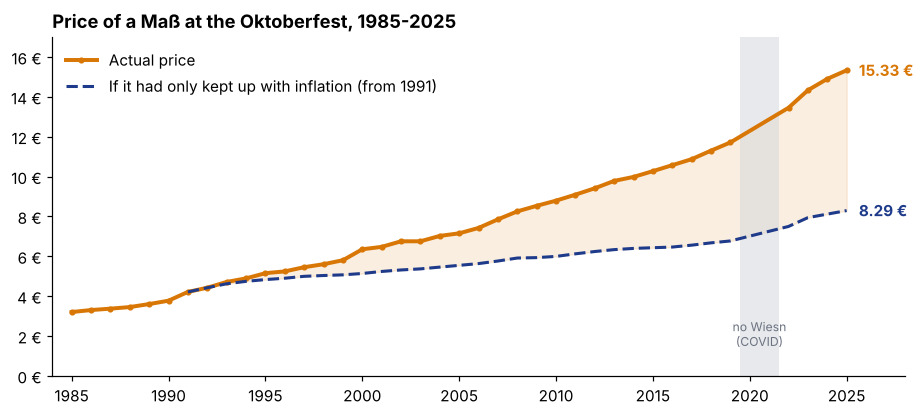

1985: 3.20 € -> 2025: 15.33 € (4.8x)
1991-2025: Maß +3.9% a year vs consumer prices +2.0% a year
1991 Maß in 2025 euros: 8.29 € -> real increase +85%


In [3]:
df = overview.merge(cpi, on="jahr", how="left")
cpi_2025 = cpi.set_index("jahr").loc[2025, "vpi"]
df["real_2025"] = df["bier_preis"] * cpi_2025 / df["vpi"]
base = df[df["jahr"] == 1991].iloc[0]
df["inflation_only"] = base["bier_preis"] * df["vpi"] / base["vpi"]
latest = df.iloc[-1]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df["jahr"], df["bier_preis"], color=GOLD, lw=2.6, marker="o", ms=3, label="Actual price")
ax.plot(df["jahr"], df["inflation_only"], color=BLUE, lw=2, ls="--", label="If it had only kept up with inflation (from 1991)")
ax.fill_between(df["jahr"], df["inflation_only"], df["bier_preis"], where=df["jahr"] >= 1991, color=GOLD, alpha=0.12)
ax.annotate(f"{latest['bier_preis']:.2f} €", (2025, latest["bier_preis"]), xytext=(8, 0), textcoords="offset points", va="center",
            color=GOLD, fontweight="bold")
ax.annotate(f"{latest['inflation_only']:.2f} €", (2025, latest["inflation_only"]), xytext=(8, 0), textcoords="offset points",
            va="center", color=BLUE, fontweight="bold")
ax.axvspan(2019.5, 2021.5, color=LIGHT, alpha=0.5, lw=0)
ax.text(2020.5, 1.5, "no Wiesn\n(COVID)", ha="center", fontsize=8, color=GREY)
ax.yaxis.set_major_formatter(euro)
ax.set_ylim(0, 17)
ax.set_xlim(1984, 2028)
ax.set_title("Price of a Maß at the Oktoberfest, 1985-2025")
ax.legend(frameon=False, loc="upper left")
fig.savefig(IMG / "01_mass_price.png")
plt.show()

cagr = lambda a, b, n: (b / a) ** (1 / n) - 1
beer_growth = cagr(base["bier_preis"], latest["bier_preis"], 2025 - 1991)
cpi_growth = cagr(base["vpi"], latest["vpi"], 2025 - 1991)
print(f"1985: {df.iloc[0]['bier_preis']:.2f} € -> 2025: {latest['bier_preis']:.2f} € ({latest['bier_preis'] / df.iloc[0]['bier_preis']:.1f}x)")
print(f"1991-2025: Maß +{beer_growth:.1%} a year vs consumer prices +{cpi_growth:.1%} a year")
print(f"1991 Maß in 2025 euros: {base['real_2025']:.2f} € -> real increase {latest['bier_preis'] / base['real_2025'] - 1:+.0%}")

A Maß cost 3.20 € in 1985 and 15.33 € in 2025, **4.8 times as much**. Since 1991 it has risen by **3.9% a year, almost double the 2.0% general inflation rate**.

In today's money, the 1991 Maß would cost 8.29 €. So even after removing inflation, **the real price of Oktoberfest beer has risen by 85%**. If it had only kept pace with inflation, a Maß would cost about 8.30 € today, not 15.33 €.

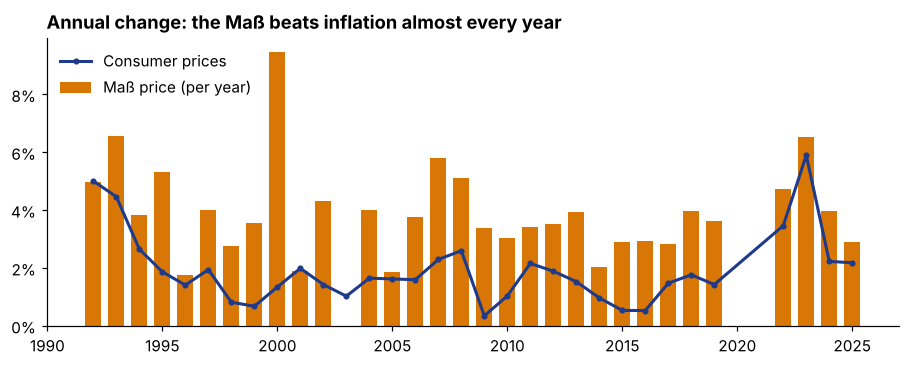

Years where the Maß rose faster than consumer prices: 91% (29 of 32)
Correlation of yearly changes: 0.49


In [4]:
yearly = df[["jahr", "bier_preis", "vpi"]].dropna().copy()
gap = yearly["jahr"].diff()
yearly["beer_change"] = (yearly["bier_preis"] / yearly["bier_preis"].shift()) ** (1 / gap) - 1
yearly["cpi_change"] = (yearly["vpi"] / yearly["vpi"].shift()) ** (1 / gap) - 1
yearly = yearly.dropna()

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(yearly["jahr"], yearly["beer_change"], color=GOLD, width=0.7, label="Maß price (per year)")
ax.plot(yearly["jahr"], yearly["cpi_change"], color=BLUE, lw=2, marker="o", ms=3, label="Consumer prices")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_title("Annual change: the Maß beats inflation almost every year")
ax.legend(frameon=False, loc="upper left")
fig.savefig(IMG / "02_annual_change.png")
plt.show()

beat = (yearly["beer_change"] > yearly["cpi_change"]).mean()
print(f"Years where the Maß rose faster than consumer prices: {beat:.0%} ({(yearly['beer_change'] > yearly['cpi_change']).sum()} of {len(yearly)})")
print(f"Correlation of yearly changes: {yearly['beer_change'].corr(yearly['cpi_change']):.2f}")

For 2022 the bar shows the average annual rise since 2019 (4.7% a year), not the raw jump of +15% across the COVID gap.

The Maß rose faster than consumer prices in 29 of 32 years. Its yearly changes move with inflation, but only loosely (correlation 0.49). The festival can do that because demand is stable: around six million visitors come whatever a Maß costs (section 5).

## 3. How long do you work for a Maß?

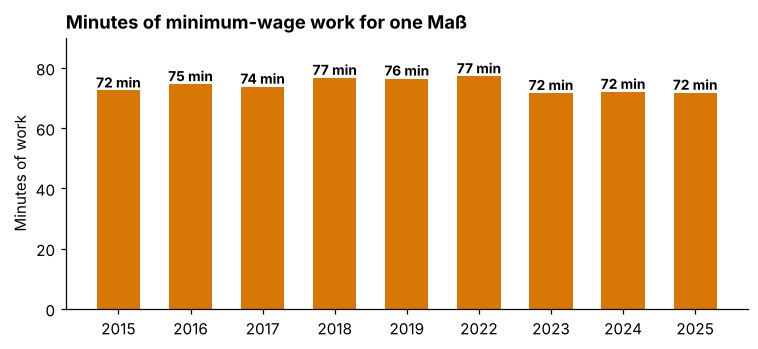

,jahr,bier_preis,mindestlohn_eur,minutes
0,2015,10.3,8.5,72.5
1,2016,10.6,8.5,74.6
2,2017,10.9,8.8,73.8
3,2018,11.3,8.8,76.7
4,2019,11.7,9.2,76.5
5,2022,13.4,10.4,77.2
6,2023,14.3,12.0,71.6
7,2024,14.9,12.4,72.0
8,2025,15.3,12.8,71.7


In [5]:
w = df.merge(wage, on="jahr")
w["minutes"] = w["bier_preis"] / w["mindestlohn_eur"] * 60

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(w["jahr"].astype(str), w["minutes"], color=GOLD, width=0.6)
for x, m in enumerate(w["minutes"]):
    ax.text(x, m + 1, f"{m:.0f} min", ha="center", fontsize=9, fontweight="bold")
ax.set_ylim(0, 90)
ax.set_ylabel("Minutes of work")
ax.set_title("Minutes of minimum-wage work for one Maß")
fig.savefig(IMG / "03_minutes.png")
plt.show()
w[["jahr", "bier_preis", "mindestlohn_eur", "minutes"]].round(1)

**For a minimum-wage worker, a Maß has cost a steady 72-77 minutes of work since 2015.** The minimum wage has risen about as fast as the Maß. The big increase to 12 € in October 2022 cut the cost from 77 minutes back to 72.

*Source and caveat:* statutory minimum wage under the German Mindestlohngesetz, using the rate in force during each Oktoberfest (see `data/raw/mindestlohn.csv`). The minimum wage only exists from 2015, so this doesn't go further back.

In [6]:
bw = wiesn.load_bavaria_wages().merge(df[["jahr", "bier_preis"]], on="jahr")
bw["mass_index"] = bw["bier_preis"] / bw.loc[bw["jahr"] == 2025, "bier_preis"].iloc[0] * 100
change = bw.set_index("jahr").loc[[2022, 2025]]
wage_rise = change.loc[2025, "nominallohn"] / change.loc[2022, "nominallohn"] - 1
mass_rise = change.loc[2025, "bier_preis"] / change.loc[2022, "bier_preis"] - 1
print(f"Bavaria 2022-2025: nominal wages {wage_rise:+.1%}, Maß {mass_rise:+.1%}")
print(f"Maß relative to the average Bavarian wage: {(1 + mass_rise) / (1 + wage_rise) - 1:+.1%}")
bw[["jahr", "nominallohn", "mass_index", "bier_preis"]].round(1)

Bavaria 2022-2025: nominal wages +16.6%, Maß +14.0%
Maß relative to the average Bavarian wage: -2.2%


,jahr,nominallohn,mass_index,bier_preis
0,2022,85.8,87.7,13.4
1,2023,91.2,93.5,14.3
2,2024,96.0,97.2,14.9
3,2025,100.0,100.0,15.3


**A second check with average wages.** Destatis's new wage index for Bavaria only starts in 2022, so it's too short for the long view, but it confirms the recent picture. From 2022 to 2025, nominal wages in Bavaria rose about 17% and the Maß rose about 14%, so **relative to the average Bavarian wage, the Maß got about 2% cheaper** after the post-COVID jump.

## 4. Which tent is cheapest?

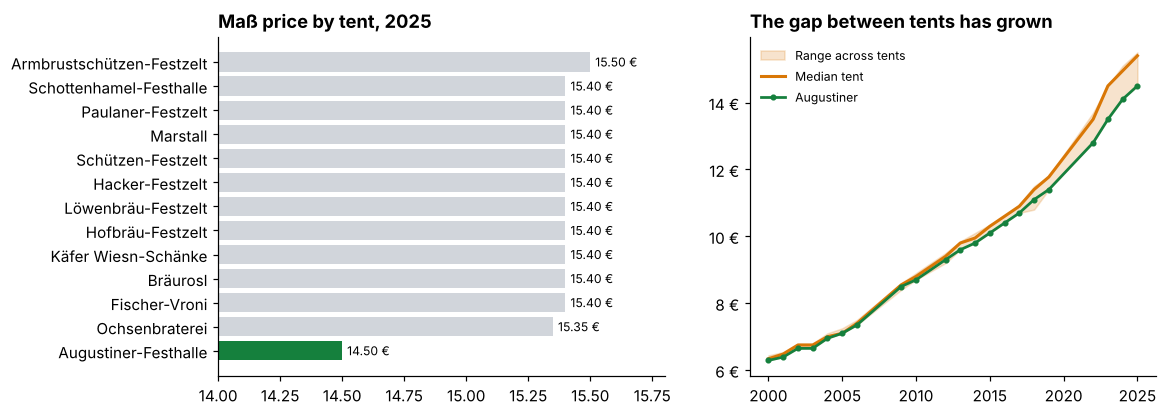

Augustiner was (one of) the cheapest in 14 of 22 years
Gap between cheapest and dearest tent: {2000: 0.15, 2010: 0.2, 2018: 0.7, 2025: 1.0}


In [7]:
latest_tents = tents[tents["jahr"] == 2025].sort_values("preis")
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
colors = [GREEN if t == "Augustiner-Festhalle" else LIGHT for t in latest_tents["tent"]]
ax.barh(latest_tents["tent"], latest_tents["preis"], color=colors)
for y, p in enumerate(latest_tents["preis"]):
    ax.text(p + 0.02, y, f"{p:.2f} €", va="center", fontsize=8)
ax.set_xlim(14, 15.8)
ax.set_title("Maß price by tent, 2025")

spread = tents.groupby("jahr")["preis"].agg(["min", "max", "median"])
cheapest = tents.loc[tents.groupby("jahr")["preis"].idxmin()].set_index("jahr")["tent"]
ax = axes[1]
ax.fill_between(spread.index, spread["min"], spread["max"], color=GOLD, alpha=0.2, label="Range across tents")
ax.plot(spread.index, spread["median"], color=GOLD, lw=2, label="Median tent")
aug = tents[tents["tent"] == "Augustiner-Festhalle"].set_index("jahr")["preis"]
ax.plot(aug.index, aug.values, color=GREEN, lw=1.8, marker="o", ms=3, label="Augustiner")
ax.yaxis.set_major_formatter(euro)
ax.set_title("The gap between tents has grown")
ax.legend(frameon=False, fontsize=8)
fig.savefig(IMG / "04_tents.png")
plt.show()

aug_share = (cheapest == "Augustiner-Festhalle").mean()
print(f"Augustiner was (one of) the cheapest in {(cheapest == 'Augustiner-Festhalle').sum()} of {len(cheapest)} years")
print("Gap between cheapest and dearest tent:", (spread["max"] - spread["min"]).loc[[2000, 2010, 2018, 2025]].round(2).to_dict())

**Augustiner is the tent you'd bet on for the cheapest Maß.** It was the cheapest in 14 of 22 years, far more than any other tent, and in 2025 it was the only big tent under 15 € (14.50 €).

The spread between tents has also grown. Until 2017 all the big tents charged within about 0.30 € of each other. Since 2022 the gap has been about 1 €, mostly because Augustiner has stayed cheaper.

## 5. More visitors? No. More beer per visitor? Yes.

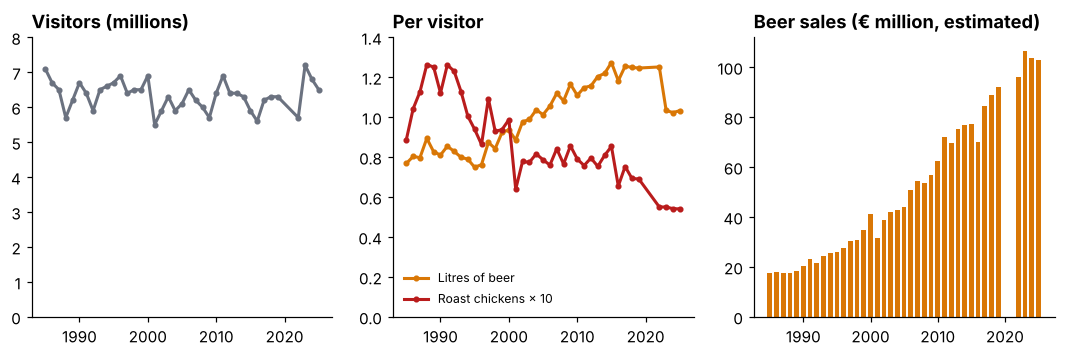

Visitors: 7.1M -> 6.5M
Beer per visitor: 0.77 l -> 1.03 l (peak 1.27 l in 2015)
Chickens per visitor: 0.089 -> 0.054
Beer sales: 17.5 M € -> 102.9 M €


In [8]:
df["beer_per_visitor"] = df["beer_litres"] / (df["besucher_gesamt"] * 1e6)
df["chicken_per_visitor"] = df["hendl_konsum"] / (df["besucher_gesamt"] * 1e6)
df["beer_revenue_m"] = df["beer_litres"] * df["bier_preis"] / 1e6

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
axes[0].plot(df["jahr"], df["besucher_gesamt"], color=GREY, lw=2, marker="o", ms=3)
axes[0].set_ylim(0, 8)
axes[0].set_title("Visitors (millions)")
axes[1].plot(df["jahr"], df["beer_per_visitor"], color=GOLD, lw=2, marker="o", ms=3, label="Litres of beer")
axes[1].plot(df["jahr"], df["chicken_per_visitor"] * 10, color=RED, lw=2, marker="o", ms=3, label="Roast chickens × 10")
axes[1].set_ylim(0, 1.4)
axes[1].set_title("Per visitor")
axes[1].legend(frameon=False, fontsize=8)
axes[2].bar(df["jahr"], df["beer_revenue_m"], color=GOLD, width=0.7)
axes[2].set_title("Beer sales (€ million, estimated)")
fig.savefig(IMG / "05_volumes.png")
plt.show()

first, last = df.iloc[0], df.iloc[-1]
print(f"Visitors: {first['besucher_gesamt']}M -> {last['besucher_gesamt']}M")
print(f"Beer per visitor: {first['beer_per_visitor']:.2f} l -> {last['beer_per_visitor']:.2f} l "
      f"(peak {df['beer_per_visitor'].max():.2f} l in {int(df.loc[df['beer_per_visitor'].idxmax(), 'jahr'])})")
print(f"Chickens per visitor: {first['chicken_per_visitor']:.3f} -> {last['chicken_per_visitor']:.3f}")
print(f"Beer sales: {first['beer_revenue_m']:.1f} M € -> {last['beer_revenue_m']:.1f} M €")

- **Visitor numbers have barely changed** in 40 years: between 5.5 and 7.2 million per festival.
- **Each visitor drinks more**: about 0.77 l in 1985, peaking at 1.27 l in 2015, and about 1.03 l in 2025, despite the rising price. Beer demand at the Wiesn is very price-insensitive.
- **Roast chicken is losing out**: from 0.09 chickens per visitor in 1985 to 0.05 today, while its price rose almost fourfold. There's a sharp drop in 2001, the year with the fewest visitors, which also coincided with Germany's BSE food scare.
- **Estimated beer sales rose from about 17 M € to about 103 M €**: almost entirely price, partly volume, and not at all more visitors. (Litres × average price; this ignores pricier specialty beers.)

## 6. Food vs beer since 2018

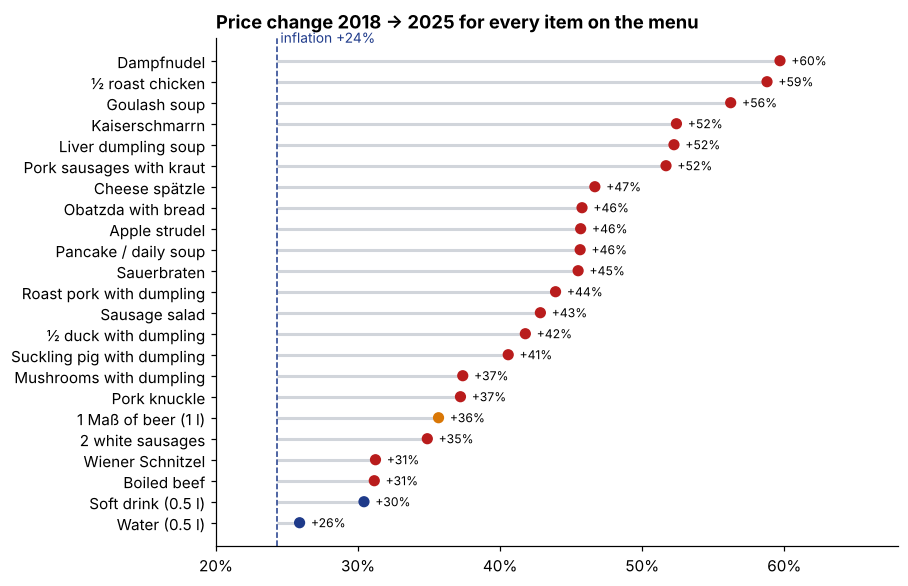

Items rising faster than inflation: 23 of 23
Median food item: +46% | Maß: +36% | Water: +26%


In [9]:
pivot = menu.pivot(index="item_en", columns="jahr", values="preis")
change = (pivot[2025] / pivot[2018] - 1).sort_values()
cpi_change = cpi.set_index("jahr").loc[2025, "vpi"] / cpi.set_index("jahr").loc[2018, "vpi"] - 1

fig, ax = plt.subplots(figsize=(8, 6))
colors = [GOLD if "Maß" in i else (BLUE if "0.5" in i else RED) for i in change.index]
ax.hlines(range(len(change)), cpi_change, change.values, color=LIGHT, lw=2)
ax.scatter(change.values, range(len(change)), color=colors, s=40, zorder=3)
ax.axvline(cpi_change, color=BLUE, ls="--", lw=1)
ax.text(cpi_change, len(change) - 0.3, f" inflation {cpi_change:+.0%}", color=BLUE, fontsize=9, va="bottom")
for y, (item, v) in enumerate(change.items()):
    ax.text(v + 0.008, y, f"{v:+.0%}", va="center", fontsize=8)
ax.set_yticks(range(len(change)), change.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlim(0.2, 0.68)
ax.set_title("Price change 2018 → 2025 for every item on the menu")
fig.savefig(IMG / "06_menu.png")
plt.show()

print(f"Items rising faster than inflation: {(change > cpi_change).sum()} of {len(change)}")
print(f"Median food item: {change.drop(['1 Maß of beer (1 l)', 'Soft drink (0.5 l)', 'Water (0.5 l)']).median():+.0%} | "
      f"Maß: {change['1 Maß of beer (1 l)']:+.0%} | Water: {change['Water (0.5 l)']:+.0%}")

**Every one of the 23 items on the menu rose faster than general inflation (+24%) between 2018 and 2025.** The Maß (+36%) was actually one of the slower risers. The typical food item rose by about 45%, and **half a roast chicken (+59%) and the Dampfnudel (+60%) rose the most**.

One explanation is that food carries the energy, staff and ingredient costs that hit hardest in 2022-23, while beer prices are set by the breweries and watched closely by the press every year. It's an interpretation, not something this data can prove.

## 7. When will a Maß cost 20 €?

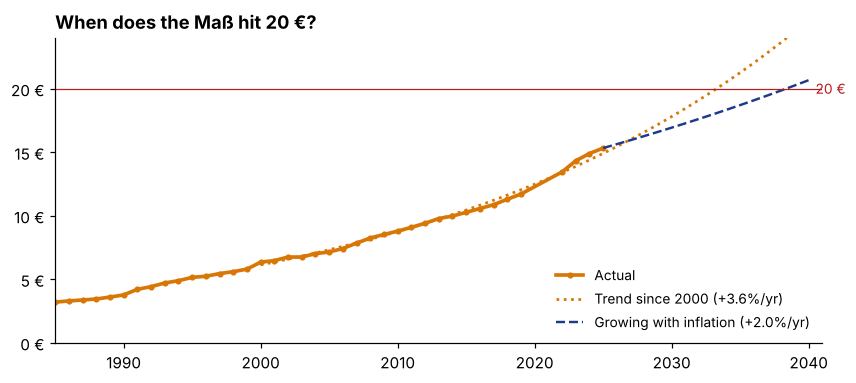

On the 2000-2025 trend: 20 € in 2033. If it only grew with inflation: 2038.


In [10]:
recent = df[df["jahr"] >= 2000]
slope, intercept = np.polyfit(recent["jahr"], np.log(recent["bier_preis"]), 1)
trend_growth = np.exp(slope) - 1
year_20 = (np.log(20) - intercept) / slope
year_20_cpi = 2025 + np.log(20 / latest["bier_preis"]) / np.log(1 + cpi_growth)

future = np.arange(2000, 2041)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(df["jahr"], df["bier_preis"], color=GOLD, lw=2.4, marker="o", ms=3, label="Actual")
ax.plot(future, np.exp(intercept + slope * future), color=GOLD, ls=":", lw=1.8, label=f"Trend since 2000 (+{trend_growth:.1%}/yr)")
cpi_path = latest["bier_preis"] * (1 + cpi_growth) ** (future[future >= 2025] - 2025)
ax.plot(future[future >= 2025], cpi_path, color=BLUE, ls="--", lw=1.6, label=f"Growing with inflation (+{cpi_growth:.1%}/yr)")
ax.axhline(20, color=RED, lw=0.8)
ax.text(2040.5, 20, "20 €", color=RED, fontsize=9, va="center")
ax.yaxis.set_major_formatter(euro)
ax.set_xlim(1985, 2041)
ax.set_ylim(0, 24)
ax.set_title("When does the Maß hit 20 €?")
ax.legend(frameon=False, loc="lower right", fontsize=9)
fig.savefig(IMG / "07_twenty_euro.png")
plt.show()
print(f"On the 2000-2025 trend: 20 € in {year_20:.0f}. If it only grew with inflation: {year_20_cpi:.0f}.")

**On its 25-year trend (+3.6% a year), the Maß crosses 20 € around 2033.** If future increases only matched average inflation, it would take until around 2038. This is a trend extrapolation, not a forecast: an energy shock like 2022 would bring it forward, and political pressure on the city could slow it down.

## 8. Takeaways

1. **The Maß is a "luxury inflation" good.** Its real price has risen 85% since 1991, while visitor numbers stayed flat and consumption per visitor went up. Demand barely reacts to price.
2. **For workers, it's held steady.** It has cost 72-77 minutes of minimum-wage work since 2015, and since 2022 Bavarian wages have risen slightly faster than the Maß.
3. **Shop around.** Augustiner is usually the cheapest tent, and the gap to the others has grown to about 1 €.
4. **Watch the food bill, not just the beer.** Every menu item has outpaced inflation since 2018, and food rose faster than beer.
5. **20 € is coming around 2033** if the long-run trend holds.

**Limitations:** these are city-published average prices, not prices actually paid. Beer sales are estimated as litres × average price. The CPI is national, not Munich-specific. The minimum wage covers only 2015 onwards.